## 1. Verilənlər

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

np.random.seed(42)
n = 200
gubre = np.random.uniform(40, 300, n)        # gübrə, kq/ha
yagis = np.random.normal(450, 90, n)         # yağış, mm
suvarma = np.random.randint(0, 2, n)         # suvarma: 0 - yox, 1 - var
mehsuldarliq = 8 + 0.075*gubre + 0.012*yagis + 4*suvarma + np.random.normal(0, 2, n)

df = pd.DataFrame({"gubre": gubre, "yagis": yagis, "suvarma": suvarma,
                   "mehsuldarliq": mehsuldarliq}).round(2)
df.head()

,gubre,yagis,suvarma,mehsuldarliq
0,137.38,388.80,0,27.09
1,287.19,470.90,1,42.70
2,230.32,476.38,1,34.49
3,195.65,385.71,0,29.25
4,80.56,617.92,0,22.75


## 2. Gübrə ilə məhsuldarlıq arasında əlaqə

gubre           0.89
yagis           0.14
suvarma         0.38
mehsuldarliq    1.00
Name: mehsuldarliq, dtype: float64


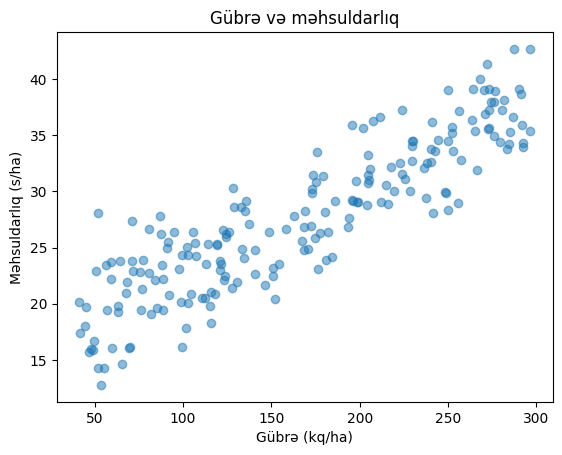

In [3]:
print(df.corr()["mehsuldarliq"].round(2))

plt.scatter(df["gubre"], df["mehsuldarliq"], alpha=0.5)
plt.xlabel("Gübrə (kq/ha)")
plt.ylabel("Məhsuldarlıq (s/ha)")
plt.title("Gübrə və məhsuldarlıq")
plt.show()

**Şərh:** Korrelyasiya yüksəkdir, yəni gübrə artdıqca məhsuldarlıq da artır.

## 3. Sadə xətti reqressiya (yalnız gübrə)

In [5]:
X = df[["gubre"]]
y = df["mehsuldarliq"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model1 = LinearRegression()
model1.fit(X_train, y_train)
train_pred1 = model1.predict(X_train)
test_pred1 = model1.predict(X_test)

print(f"Tənlik: məhsuldarlıq = {model1.intercept_:.2f} + {model1.coef_[0]:.4f} * gübrə")

res1 = pd.DataFrame({
    "Train": [r2_score(y_train, train_pred1), mean_absolute_error(y_train, train_pred1), mean_squared_error(y_train, train_pred1)],
    "Test":  [r2_score(y_test, test_pred1),   mean_absolute_error(y_test, test_pred1),   mean_squared_error(y_test, test_pred1)]
}, index=["R2", "MAE", "MSE"]).round(3)
res1

Tənlik: məhsuldarlıq = 14.87 + 0.0782 * gübrə


,Train,Test
R2,0.799,0.743
MAE,2.494,2.517
MSE,9.025,10.303


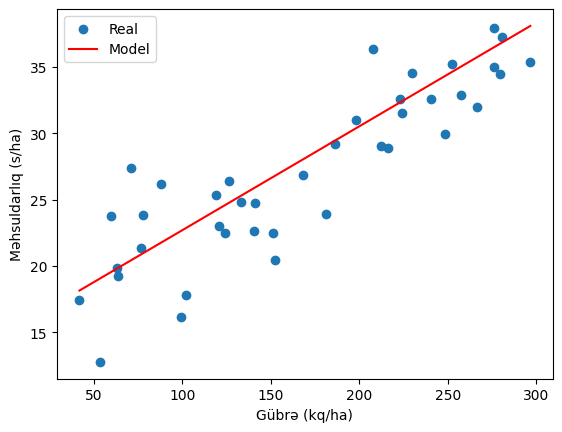

In [6]:
xs = X_test.sort_values("gubre")
plt.scatter(X_test, y_test, label="Real")
plt.plot(xs, model1.predict(xs), "r", label="Model")
plt.xlabel("Gübrə (kq/ha)"); plt.ylabel("Məhsuldarlıq (s/ha)")
plt.legend(); plt.show()

## 4. Çoxdəyişənli xətti reqressiya (gübrə + yağış + suvarma)

In [7]:
X2 = df[["gubre", "yagis", "suvarma"]]
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y, test_size=0.2, random_state=42)

model2 = LinearRegression()
model2.fit(X2_train, y2_train)
train_pred2 = model2.predict(X2_train)
test_pred2 = model2.predict(X2_test)

print("Əmsallar:", dict(zip(X2.columns, [round(float(k), 4) for k in model2.coef_])))

res2 = pd.DataFrame({
    "Train": [r2_score(y2_train, train_pred2), mean_absolute_error(y2_train, train_pred2), mean_squared_error(y2_train, train_pred2)],
    "Test":  [r2_score(y2_test, test_pred2),   mean_absolute_error(y2_test, test_pred2),   mean_squared_error(y2_test, test_pred2)]
}, index=["R2", "MAE", "MSE"]).round(3)
res2

Əmsallar: {'gubre': 0.0747, 'yagis': 0.0129, 'suvarma': 4.0566}


,Train,Test
R2,0.908,0.899
MAE,1.633,1.628
MSE,4.143,4.043


## 5. Müqayisə

In [8]:
pd.DataFrame({"Sadə model": res1["Test"], "Çoxdəyişənli model": res2["Test"]})

,Sadə model,Çoxdəyişənli model
R2,0.743,0.899
MAE,2.517,1.628
MSE,10.303,4.043


## 6. Nəticə
- Gübrə miqdarı ilə məhsuldarlıq arasında güclü müsbət xətti əlaqə var.
- Çoxdəyişənli modelin R² dəyəri daha yüksək, xətaları (MAE, RMSE) daha azdır, yəni o, daha dəqiqdir.
- Deməli, məhsuldarlığa gübrədən başqa yağış və suvarma da təsir edir.